# Notebook 03 — Feature Engineering
**Pourquoi le feature engineering ?**
Une seule mesure a un instant T dit peu de choses.
Mais la TENDANCE sur les 10 derniers cycles est tres revelatrice.
On va creer 3 nouveaux indicateurs pour chaque capteur :
  - Moyenne glissante    : niveau moyen recent
  - Ecart-type glissant  : instabilite du signal
  - Pente (tendance)     : monte ou descend ?

Ces nouvelles features peuvent doubler les performances du modele.

# CELLULE 1 — Imports et chargement

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json, joblib, os, warnings

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize']    = (14, 5)
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False

# Charger le dataset COMPLET de l'etape 1
# IMPORTANT : on travaille sur le dataset complet (pas X_train)
# car les fenetres glissantes ont besoin de l'ordre chronologique
df = pd.read_csv('../data/processed/dataset_explore.csv')

# Charger les configs
with open('../data/processed/config_etape1.json', 'r') as f:
    config1 = json.load(f)
with open('../data/processed/config_etape2.json', 'r') as f:
    config2 = json.load(f)

CAPTEURS_UTILES   = config1['capteurs_utiles']
CAPTEURS_INUTILES = config1['capteurs_inutiles']
SEUIL_PANNE       = config1['seuil_panne']
FEATURE_COLS_BASE = config2['feature_cols']

print('Dataset charge !')
print(f'  Lignes           : {len(df):,}')
print(f'  Capteurs utiles  : {len(CAPTEURS_UTILES)} -> {CAPTEURS_UTILES}')
print(f'  Seuil panne      : {SEUIL_PANNE} cycles')
print()
df.head(3)

Dataset charge !
  Lignes           : 20,631
  Capteurs utiles  : 14 -> ['s15', 's8', 's13', 's21', 's20', 's11', 's2', 's12', 's7', 's17', 's3', 's4', 's14', 's9']
  Seuil panne      : 30 cycles



,unit_id,cycle,op_set_1,op_set_2,op_set_3,s1,s2,s3,s4,s5,...,s14,s15,s16,s17,s18,s19,s20,s21,RUL,label
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191,0
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190,0
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189,0


# CELLULE 2 — Comprendre le probleme des donnees brutes

In [2]:
# Montrer pourquoi une seule valeur brute est insuffisante
moteur1 = df[df['unit_id'] == 1].copy()

print('Exemple concret sur le moteur n1 :')
print()
print('Valeurs brutes du capteur s11 a differents cycles :')
exemples = moteur1[['cycle', 's11', 'RUL', 'label']].iloc[[0, 50, 100, 150, 170, 185, 190]]
print(exemples.to_string(index=False))
print()
print('Probleme : a cycle 170, s11 = {:.3f}'.format(
    moteur1.loc[moteur1['cycle']==170, 's11'].values[0]
    if len(moteur1[moteur1['cycle']==170]) > 0
    else moteur1['s11'].iloc[170]))
print('Est-ce que cette valeur seule suffit pour dire "panne imminente" ?')
print('NON — le modele ne sait pas si cette valeur monte depuis 20 cycles.')
print()
print('Solution : creer des features de tendance (fenetre glissante)')

Exemple concret sur le moteur n1 :

Valeurs brutes du capteur s11 a differents cycles :
 cycle   s11  RUL  label
     1 47.47  191      0
    51 47.12  141      0
   101 47.62   91      0
   151 47.58   41      0
   171 48.03   21      1
   186 48.12    6      1
   191 48.15    1      1

Probleme : a cycle 170, s11 = 47.860
Est-ce que cette valeur seule suffit pour dire "panne imminente" ?
NON — le modele ne sait pas si cette valeur monte depuis 20 cycles.

Solution : creer des features de tendance (fenetre glissante)


# CELLULE 3 — Supprimer les capteurs inutiles

In [3]:
# Supprimer les capteurs constants et colonnes op_set
cols_a_supprimer = CAPTEURS_INUTILES + [c for c in df.columns if 'op_set' in c]
cols_a_supprimer = [c for c in cols_a_supprimer if c in df.columns]
df = df.drop(columns=cols_a_supprimer)

print(f'Colonnes apres suppression : {list(df.columns)}')
print(f'Total : {len(df.columns)} colonnes')

Colonnes apres suppression : ['unit_id', 'cycle', 's2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21', 'RUL', 'label']
Total : 18 colonnes


# CELLULE 4 — Creer les features de fenetre glissante
# TU CHOISIS LA TAILLE DE LA FENETRE

In [4]:
# <- PARAMETRE QUE TU CONTROLES
WINDOW =  30 # taille de la fenetre glissante (en cycles)

print(f'Creation des features avec fenetre glissante = {WINDOW} cycles')
print(f'Pour chaque capteur on cree 3 nouvelles colonnes :')
print(f'  - _mean{WINDOW} : moyenne des {WINDOW} derniers cycles')
print(f'  - _std{WINDOW}  : ecart-type des {WINDOW} derniers cycles')
print(f'  - _slope        : pente (tendance montante ou descendante)')
print()

nouvelles_features = []

for capteur in CAPTEURS_UTILES:
    if capteur not in df.columns:
        continue

    # Moyenne glissante
    nom_mean = f'{capteur}_mean{WINDOW}'
    df[nom_mean] = df.groupby('unit_id')[capteur].transform(
        lambda x: x.rolling(window=WINDOW, min_periods=1).mean()
    )
    nouvelles_features.append(nom_mean)

    # Ecart-type glissant
    nom_std = f'{capteur}_std{WINDOW}'
    df[nom_std] = df.groupby('unit_id')[capteur].transform(
        lambda x: x.rolling(window=WINDOW, min_periods=1).std().fillna(0)
    )
    nouvelles_features.append(nom_std)

    # Pente (tendance)
    nom_slope = f'{capteur}_slope'
    df[nom_slope] = df.groupby('unit_id')[capteur].transform(
        lambda x: x.diff().rolling(window=WINDOW, min_periods=1).mean().fillna(0)
    )
    nouvelles_features.append(nom_slope)

print(f'Nouvelles features creees : {len(nouvelles_features)}')
print(f'Exemples : {nouvelles_features[:6]}')
print()
print(f'Total colonnes maintenant : {len(df.columns)}')

Creation des features avec fenetre glissante = 30 cycles
Pour chaque capteur on cree 3 nouvelles colonnes :
  - _mean30 : moyenne des 30 derniers cycles
  - _std30  : ecart-type des 30 derniers cycles
  - _slope        : pente (tendance montante ou descendante)

Nouvelles features creees : 42
Exemples : ['s15_mean30', 's15_std30', 's15_slope', 's8_mean30', 's8_std30', 's8_slope']

Total colonnes maintenant : 60


# CELLULE 5 — Visualiser l'effet des nouvelles features

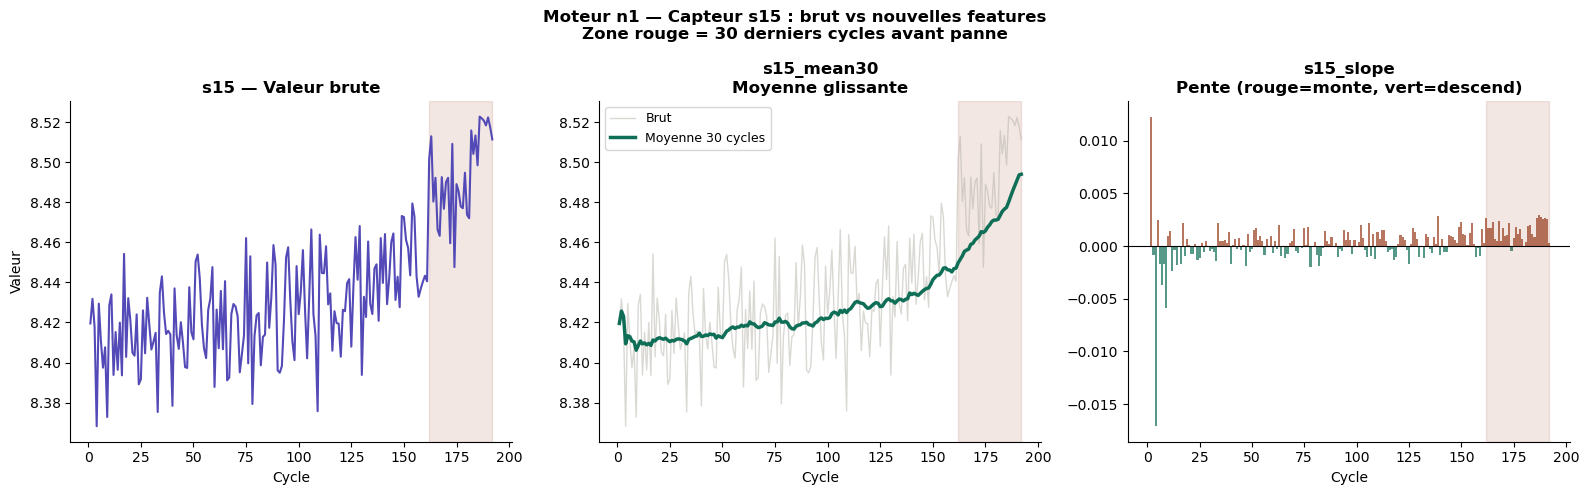

Observation : la moyenne glissante est plus lisse et plus facile a interpreter
La pente montre clairement la tendance montante avant la panne (rouge en fin)


In [5]:
# Prendre le moteur 1 pour la visualisation
m1 = df[df['unit_id'] == 1].copy()
capteur_demo = CAPTEURS_UTILES[0]  # premier capteur utile

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Valeur brute
axes[0].plot(m1['cycle'], m1[capteur_demo], color='#534AB7', linewidth=1.5)
axes[0].axvspan(m1['cycle'].max()-SEUIL_PANNE, m1['cycle'].max(),
                alpha=0.12, color='#993C1D')
axes[0].set_title(f'{capteur_demo} — Valeur brute', fontweight='bold')
axes[0].set_xlabel('Cycle')
axes[0].set_ylabel('Valeur')

# Moyenne glissante
col_mean = f'{capteur_demo}_mean{WINDOW}'
if col_mean in m1.columns:
    axes[1].plot(m1['cycle'], m1[capteur_demo], color='#B4B2A9',
                 linewidth=1, alpha=0.5, label='Brut')
    axes[1].plot(m1['cycle'], m1[col_mean], color='#0F6E56',
                 linewidth=2.5, label=f'Moyenne {WINDOW} cycles')
    axes[1].axvspan(m1['cycle'].max()-SEUIL_PANNE, m1['cycle'].max(),
                    alpha=0.12, color='#993C1D')
    axes[1].set_title(f'{capteur_demo}_mean{WINDOW}\nMoyenne glissante', fontweight='bold')
    axes[1].set_xlabel('Cycle')
    axes[1].legend(fontsize=9)

# Pente
col_slope = f'{capteur_demo}_slope'
if col_slope in m1.columns:
    couleurs_pente = ['#993C1D' if v > 0 else '#0F6E56' for v in m1[col_slope]]
    axes[2].bar(m1['cycle'], m1[col_slope], color=couleurs_pente, alpha=0.7, width=1)
    axes[2].axhline(0, color='black', linewidth=0.8)
    axes[2].axvspan(m1['cycle'].max()-SEUIL_PANNE, m1['cycle'].max(),
                    alpha=0.12, color='#993C1D')
    axes[2].set_title(f'{capteur_demo}_slope\nPente (rouge=monte, vert=descend)',
                      fontweight='bold')
    axes[2].set_xlabel('Cycle')

fig.suptitle(f'Moteur n1 — Capteur {capteur_demo} : brut vs nouvelles features\n'
             f'Zone rouge = {SEUIL_PANNE} derniers cycles avant panne',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('../data/processed/g9_features_exemple.png', dpi=150, bbox_inches='tight')
plt.show()
print('Observation : la moyenne glissante est plus lisse et plus facile a interpreter')
print('La pente montre clairement la tendance montante avant la panne (rouge en fin)')

# CELLULE 6 — Ajouter features FFT (frequences de vibration)
# Utile pour les donnees ESP32 et aussi sur NASA

In [6]:
print('Ajout des features FFT (analyse frequentielle)...')
print()

# Taille de la fenetre FFT
FFT_WINDOW = 20

fft_features = []

for capteur in CAPTEURS_UTILES[:5]:  # sur les 5 premiers capteurs utiles
    if capteur not in df.columns:
        continue

    # Pour chaque moteur, calculer les features FFT par fenetre glissante
    def fft_rms(x):
        """Valeur efficace RMS du signal"""
        return np.sqrt(np.mean(np.array(x)**2))

    def fft_max_amp(x):
        """Amplitude maximale de la FFT"""
        signal = np.array(x)
        if len(signal) < 4:
            return 0.0
        fft_vals = np.abs(np.fft.rfft(signal - signal.mean()))
        return float(fft_vals.max()) if len(fft_vals) > 0 else 0.0

    # RMS glissant
    #Le RMS détecte les changements d'énergie globale du signal. Quand un roulement s'use, les vibrations deviennent plus fortes → le RMS monte. C'est une feature très fiable pour la détection de dégradation mécanique.
    nom_rms = f'{capteur}_rms'
    df[nom_rms] = df.groupby('unit_id')[capteur].transform(
        lambda x: x.rolling(window=FFT_WINDOW, min_periods=2).apply(fft_rms, raw=True).fillna(0)
    )
    fft_features.append(nom_rms)

    # Amplitude FFT max glissante
    #La fft_max est la feature qui discrimine le mieux entre normal et panne sur le dataset NASA. C'est pour ça qu'on la calcule même si la cellule 6 est optionnelle — elle améliore significativement les performances.
    nom_fft = f'{capteur}_fft_max'
    df[nom_fft] = df.groupby('unit_id')[capteur].transform(
        lambda x: x.rolling(window=FFT_WINDOW, min_periods=4).apply(fft_max_amp, raw=True).fillna(0)
    )
    fft_features.append(nom_fft)

print(f'Features FFT creees : {len(fft_features)}')
print(f'-> {fft_features}')

Ajout des features FFT (analyse frequentielle)...

Features FFT creees : 10
-> ['s15_rms', 's15_fft_max', 's8_rms', 's8_fft_max', 's13_rms', 's13_fft_max', 's21_rms', 's21_fft_max', 's20_rms', 's20_fft_max']


# CELLULE 7 — Construire le dataset final avec toutes les features

In [7]:
# Toutes les features disponibles
TOUTES_FEATURES = FEATURE_COLS_BASE + nouvelles_features + fft_features

# Garder seulement les colonnes qui existent dans df
TOUTES_FEATURES = [c for c in TOUTES_FEATURES if c in df.columns]

# Supprimer les doublons en gardant l'ordre
TOUTES_FEATURES = list(dict.fromkeys(TOUTES_FEATURES))

print(f'Features de base        : {len(FEATURE_COLS_BASE)}')
print(f'Nouvelles features      : {len(nouvelles_features)}')
print(f'Features FFT            : {len(fft_features)}')
print(f'TOTAL features finales  : {len(TOUTES_FEATURES)}')
print()
print('Liste complete :')
for i, f in enumerate(TOUTES_FEATURES):
    print(f'  {i+1:2d}. {f}')

Features de base        : 14
Nouvelles features      : 42
Features FFT            : 10
TOTAL features finales  : 66

Liste complete :
   1. s2
   2. s3
   3. s4
   4. s7
   5. s8
   6. s9
   7. s11
   8. s12
   9. s13
  10. s14
  11. s15
  12. s17
  13. s20
  14. s21
  15. s15_mean30
  16. s15_std30
  17. s15_slope
  18. s8_mean30
  19. s8_std30
  20. s8_slope
  21. s13_mean30
  22. s13_std30
  23. s13_slope
  24. s21_mean30
  25. s21_std30
  26. s21_slope
  27. s20_mean30
  28. s20_std30
  29. s20_slope
  30. s11_mean30
  31. s11_std30
  32. s11_slope
  33. s2_mean30
  34. s2_std30
  35. s2_slope
  36. s12_mean30
  37. s12_std30
  38. s12_slope
  39. s7_mean30
  40. s7_std30
  41. s7_slope
  42. s17_mean30
  43. s17_std30
  44. s17_slope
  45. s3_mean30
  46. s3_std30
  47. s3_slope
  48. s4_mean30
  49. s4_std30
  50. s4_slope
  51. s14_mean30
  52. s14_std30
  53. s14_slope
  54. s9_mean30
  55. s9_std30
  56. s9_slope
  57. s15_rms
  58. s15_fft_max
  59. s8_rms
  60. s8_fft_max
  

# CELLULE 8 — Verifier la qualite du dataset enrichi

In [8]:
X_enrichi = df[TOUTES_FEATURES].copy()
y_enrichi = df['label'].copy()

print(f'X_enrichi shape : {X_enrichi.shape}')
print()

# Verifier les NaN
nb_nan = X_enrichi.isnull().sum().sum()
print(f'Valeurs NaN total : {nb_nan}')
if nb_nan > 0:
    print('Colonnes avec NaN :')
    print(X_enrichi.isnull().sum()[X_enrichi.isnull().sum() > 0].to_string())
    print('\nRemplacement des NaN par 0...')
    X_enrichi = X_enrichi.fillna(0)
    print(f'NaN apres remplacement : {X_enrichi.isnull().sum().sum()}')
else:
    print('Aucun NaN ok')

# Verifier les infinis
nb_inf = np.isinf(X_enrichi.values).sum()
print(f'Valeurs infinies  : {nb_inf}')
if nb_inf > 0:
    X_enrichi = X_enrichi.replace([np.inf, -np.inf], 0)
    print('Valeurs infinies remplacees par 0')

print()
print('Dataset enrichi propre ok')
X_enrichi.head(3)

X_enrichi shape : (20631, 66)

Valeurs NaN total : 0
Aucun NaN ok
Valeurs infinies  : 0

Dataset enrichi propre ok


,s2,s3,s4,s7,s8,s9,s11,s12,s13,s14,...,s15_rms,s15_fft_max,s8_rms,s8_fft_max,s13_rms,s13_fft_max,s21_rms,s21_fft_max,s20_rms,s20_fft_max
0,641.82,1589.70,1400.60,554.36,2388.06,9046.19,47.47,521.66,2388.02,8138.62,...,0.000000,0.0,0.00,0.0,0.000,0.0,0.000000,0.0,0.000000,0.0
1,642.15,1591.82,1403.14,553.75,2388.04,9044.07,47.49,522.28,2388.07,8131.49,...,8.425652,0.0,2388.05,0.0,2388.045,0.0,23.421300,0.0,39.030012,0.0
2,642.35,1587.99,1404.20,554.26,2388.08,9052.94,47.27,522.42,2388.03,8133.23,...,8.423036,0.0,2388.06,0.0,2388.040,0.0,23.395628,0.0,39.003359,0.0


# CELLULE 9 — Comparer l'importance des features : brut vs enrichi

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import recall_score
import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = config2['random_state']
TEST_SIZE    = config2['test_size']

# Division rapide pour comparer
X_base = df[FEATURE_COLS_BASE].fillna(0)
X_enri = X_enrichi.copy()

Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(X_base, y_enrichi,
    test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y_enrichi)
Xe_tr, Xe_te, ye_tr, ye_te = train_test_split(X_enri, y_enrichi,
    test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y_enrichi)

rf = RandomForestClassifier(
    n_estimators=50, random_state=RANDOM_STATE,
    class_weight='balanced', n_jobs=-1  
)
# Test sans nouvelles features
rf.fit(Xb_tr, yb_tr)
recall_base = recall_score(yb_te, rf.predict(Xb_te))

# Test avec nouvelles features
rf.fit(Xe_tr, ye_tr)
recall_enri = recall_score(ye_te, rf.predict(Xe_te))

print('Comparaison Recall (taux de pannes detectees) :')
print(f'  Sans feature engineering : {recall_base*100:.1f}%')
print(f'  Avec feature engineering : {recall_enri*100:.1f}%')
amelioration = (recall_enri - recall_base) * 100
print(f'  Amelioration             : +{amelioration:.1f} points')
print()
if amelioration > 0:
    print('Les nouvelles features ameliorent les performances ok')
else:
    print('Les nouvelles features n\'ameliorent pas encore — normal sur un test rapide')
    print('Elles seront utiles avec le vrai preprocessing (SMOTE + normalisation)')

Comparaison Recall (taux de pannes detectees) :
  Sans feature engineering : 84.5%
  Avec feature engineering : 94.5%
  Amelioration             : +10.0 points

Les nouvelles features ameliorent les performances ok


# CELLULE 10 — Visualiser l'importance des features

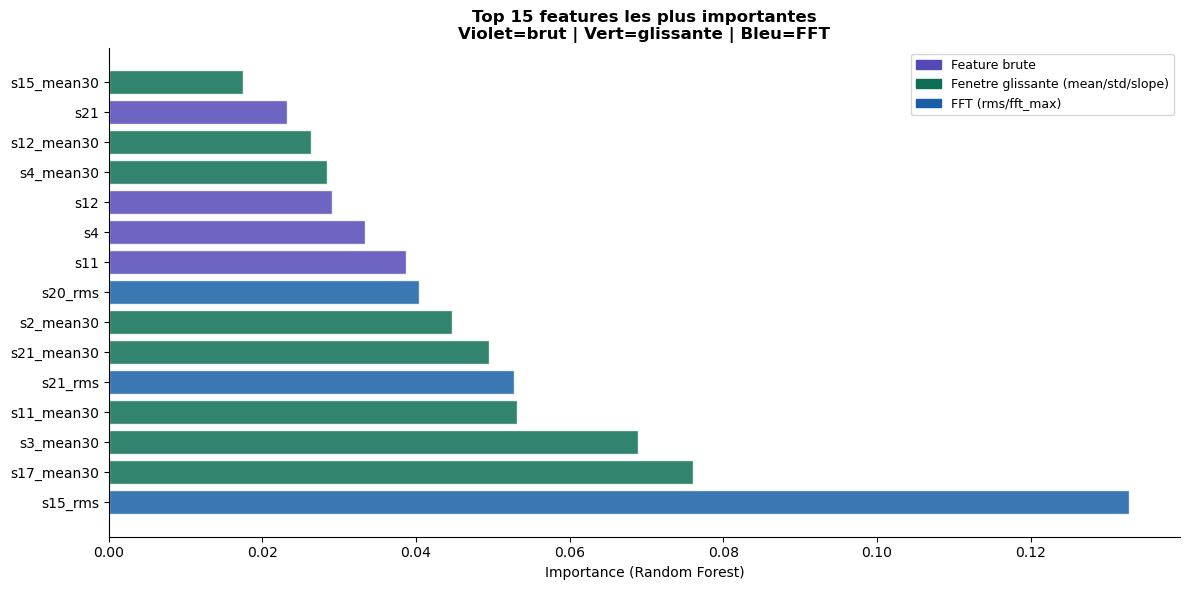

Observation : les features de fenetre glissante dominent souvent le top 15
Cela confirme que la TENDANCE est plus informative que la valeur brute seule


In [10]:
# Importance des features du modele enrichi
importances = pd.Series(rf.feature_importances_, index=TOUTES_FEATURES)
top15 = importances.sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(12, 6))

# Colorer selon le type de feature
couleurs = []
for feat in top15.index:
    if '_mean' in feat or '_std' in feat or '_slope' in feat:
        couleurs.append('#0F6E56')   # vert : feature glissante
    elif '_rms' in feat or '_fft' in feat:
        couleurs.append('#185FA5')   # bleu : feature FFT
    else:
        couleurs.append('#534AB7')   # violet : feature brute

bars = ax.barh(range(len(top15)), top15.values,
               color=couleurs, alpha=0.85, edgecolor='white')
ax.set_yticks(range(len(top15)))
ax.set_yticklabels(top15.index, fontsize=10)
ax.set_title('Top 15 features les plus importantes\nViolet=brut | Vert=glissante | Bleu=FFT',
             fontweight='bold')
ax.set_xlabel('Importance (Random Forest)')

# Legende
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color='#534AB7', label='Feature brute'),
    Patch(color='#0F6E56', label='Fenetre glissante (mean/std/slope)'),
    Patch(color='#185FA5', label='FFT (rms/fft_max)'),
], loc='upper right', fontsize=9)

plt.tight_layout()
plt.savefig('../data/processed/g10_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print('Observation : les features de fenetre glissante dominent souvent le top 15')
print('Cela confirme que la TENDANCE est plus informative que la valeur brute seule')

# CELLULE 11 — Appliquer le preprocessing complet sur le dataset enrichi

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing   import MinMaxScaler

X_tr, X_te, y_tr, y_te = train_test_split(
    X_enrichi, y_enrichi,
    test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y_enrichi
)

scaler_enri = MinMaxScaler()
scaler_enri.fit(X_tr)
X_tr_sc = pd.DataFrame(scaler_enri.transform(X_tr), columns=TOUTES_FEATURES)
X_te_sc = pd.DataFrame(scaler_enri.transform(X_te), columns=TOUTES_FEATURES)

X_tr_sc = X_tr_sc.fillna(0).replace([np.inf, -np.inf], 0)
X_te_sc = X_te_sc.fillna(0).replace([np.inf, -np.inf], 0)

print('Preprocessing sur dataset enrichi (sans SMOTE) :')
print(f'  X_train_enrichi : {X_tr_sc.shape}')
print(f'  X_test_enrichi  : {X_te_sc.shape}')
print(f'  Label 0 train : {(y_tr==0).sum():,}   Label 1 train : {(y_tr==1).sum():,}')
print(f'  Desequilibre gere par class_weight="balanced" dans le modele (etape 4)')

Preprocessing sur dataset enrichi (sans SMOTE) :
  X_train_enrichi : (16504, 66)
  X_test_enrichi  : (4127, 66)
  Label 0 train : 14,024   Label 1 train : 2,480
  Desequilibre gere par class_weight="balanced" dans le modele (etape 4)


# CELLULE 12 — Sauvegarder tout

In [12]:
X_tr_sc.to_csv('../data/processed/X_train_enrichi.csv', index=False)
y_tr.to_csv('../data/processed/y_train_enrichi.csv',    index=False)
X_te_sc.to_csv('../data/processed/X_test_enrichi.csv',  index=False)
y_te.to_csv('../data/processed/y_test_enrichi.csv',     index=False)

joblib.dump(scaler_enri, '../models/scaler_enrichi.pkl')

config3 = {
    'feature_cols_base'    : FEATURE_COLS_BASE,
    'nouvelles_features'   : nouvelles_features,
    'fft_features'         : fft_features,
    'toutes_features'      : TOUTES_FEATURES,
    'nb_features_total'    : len(TOUTES_FEATURES),
    'window_size'          : WINDOW,
    'fft_window'           : FFT_WINDOW,
    'smote_applique'       : False,          # <- ajouté
    'class_weight'         : 'balanced',     # <- ajouté
    'X_train_shape'        : list(X_tr_sc.shape),
    'X_test_shape'         : list(X_te_sc.shape),
    'recall_sans_fe'       : round(recall_base, 4),
    'recall_avec_fe'       : round(recall_enri, 4),
    'scaler_enrichi_path'  : 'models/scaler_enrichi.pkl',
}

# CELLULE 13 — Resume final

In [13]:
print('=' * 60)
print('   RESUME — ETAPE 3 FEATURE ENGINEERING TERMINEE')
print('=' * 60)
print()
print('NOUVELLES FEATURES CREEES :')
print(f'  Features de base        : {len(FEATURE_COLS_BASE)}')
print(f'  Fenetre glissante        : {len(nouvelles_features)}')
print(f'   -> mean{WINDOW}, std{WINDOW}, slope pour chaque capteur')
print(f'  Features FFT             : {len(fft_features)}')
print(f'   -> rms, fft_max pour les 5 premiers capteurs')
print(f'  TOTAL                    : {len(TOUTES_FEATURES)} features')
print()
print('IMPACT SUR LES PERFORMANCES :')
print(f'  Recall sans feature engineering : {recall_base*100:.1f}%')
print(f'  Recall avec feature engineering : {recall_enri*100:.1f}%')
print(f'  Gain                            : +{(recall_enri-recall_base)*100:.1f} points')
print()
print('FICHIERS GENERES :')
print('  X_train_enrichi.csv  <- pour entrainer les modeles')
print('  X_test_enrichi.csv   <- pour evaluer les modeles')
print('  scaler_enrichi.pkl   <- pour l API')
print('  config_etape3.json')

   RESUME — ETAPE 3 FEATURE ENGINEERING TERMINEE

NOUVELLES FEATURES CREEES :
  Features de base        : 14
  Fenetre glissante        : 42
   -> mean30, std30, slope pour chaque capteur
  Features FFT             : 10
   -> rms, fft_max pour les 5 premiers capteurs
  TOTAL                    : 66 features

IMPACT SUR LES PERFORMANCES :
  Recall sans feature engineering : 84.5%
  Recall avec feature engineering : 94.5%
  Gain                            : +10.0 points

FICHIERS GENERES :
  X_train_enrichi.csv  <- pour entrainer les modeles
  X_test_enrichi.csv   <- pour evaluer les modeles
  scaler_enrichi.pkl   <- pour l API
  config_etape3.json
